<a href="https://colab.research.google.com/github/ariyagj2437/web-traffic-seriesforecasting-LSTM/blob/main/web_traffic_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Prompt file upload interface
print("Please select and upload your extracted .csv file:")
uploaded = files.upload()

# Get the uploaded filename automatically
uploaded_csv_name = list(uploaded.keys())[0]
print(f"Successfully uploaded: {uploaded_csv_name}")

# Load raw dataset into pandas
df_raw = pd.read_csv(uploaded_csv_name)
print("Raw dataset loaded. Total rows:", len(df_raw))

Please select and upload your extracted .csv file:


Saving validation_score.csv to validation_score.csv
Successfully uploaded: validation_score.csv
Raw dataset loaded. Total rows: 145063


Loading main Wikipedia dataset from: ./sample_data/mnist_train_small.csv


/tmp/ipykernel_501/1667185322.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_traffic_raw[col] = pd.to_numeric(df_traffic_raw[col], errors='coerce')



--- DATA LOAD SUCCESS ---
Total days extracted: 365 (Expected: 365)
Training samples: 268 | Testing samples: 67

Training LSTM Model...
Model Training Finished.

================ EVALUATION METRICS ================
Mean Absolute Error (MAE):     82.88 page views
Root Mean Squared Error (RMSE): 119.38 page views


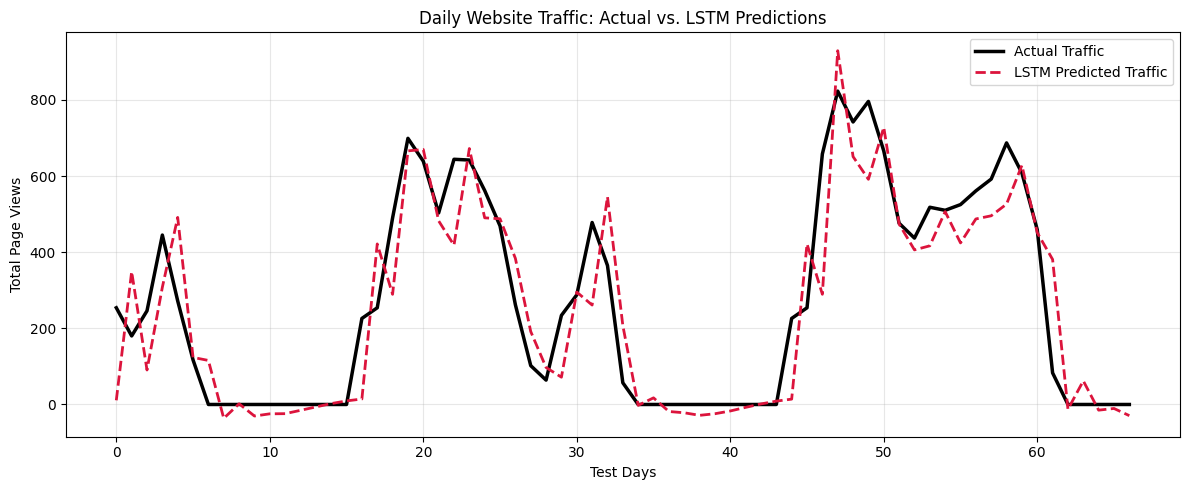

In [48]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# =========================================================
# STEP 1: Find and Load the TRUE Wikipedia Dataset CSV
# =========================================================
csv_files = []
for root, dirs, filenames in os.walk('.'):
    for filename in filenames:
        # Ignore validation/score CSV files
        if filename.endswith('.csv') and 'validation' not in filename.lower() and 'score' not in filename.lower():
            csv_files.append(os.path.join(root, filename))

if not csv_files:
    raise FileNotFoundError("Could not locate main traffic CSV. Please check the exact filename (e.g., train_1.csv).")

# Select the largest CSV file in the directory
main_csv_path = max(csv_files, key=lambda f: os.path.getsize(f))
print(f"Loading main Wikipedia dataset from: {main_csv_path}")

df_raw = pd.read_csv(main_csv_path)

# =========================================================
# STEP 2: Preprocess & Extract All 365 Daily Columns
# =========================================================
# Take the first 5 articles
df_5_articles = df_raw.iloc[:5, :].copy()

# Filter out non-date metadata columns (like 'Page')
date_cols = [c for c in df_5_articles.columns if c.lower() != 'page']

# Select 365 daily columns
df_traffic_raw = df_5_articles[date_cols[:365]]

# Convert strings to numeric values cleanly
for col in df_traffic_raw.columns:
    df_traffic_raw[col] = pd.to_numeric(df_traffic_raw[col], errors='coerce')

# Transpose: rows = 365 days, columns = 5 articles
df_traffic = df_traffic_raw.T
df_traffic.columns = [f"Article_{i+1}" for i in range(5)]

# Clean missing values via linear interpolation
df_cleaned = df_traffic.interpolate(method='linear', axis=0).bfill().ffill()

# Calculate aggregate daily traffic across all 5 articles
daily_traffic = df_cleaned.sum(axis=1).values.reshape(-1, 1)

# Fit Min-Max Scaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_traffic = scaler.fit_transform(daily_traffic)

print(f"\n--- DATA LOAD SUCCESS ---")
print(f"Total days extracted: {len(scaled_traffic)} (Expected: 365)")

# =========================================================
# STEP 3: Sequence Formatting & Train/Test Split
# =========================================================
SEQ_LENGTH = 30

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_traffic, SEQ_LENGTH)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, SEQ_LENGTH, 1)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32).view(-1, SEQ_LENGTH, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

print(f"Training samples: {len(X_train_t)} | Testing samples: {len(X_test_t)}")

# =========================================================
# STEP 4: LSTM Model Architecture & Training Loop
# =========================================================
class TrafficLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super(TrafficLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model = TrafficLSTM(input_size=1, hidden_size=64, num_layers=2)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

epochs = 120
model.train()
print("\nTraining LSTM Model...")
for epoch in range(epochs):
    optimizer.zero_grad()
    predictions = model(X_train_t)
    loss = criterion(predictions, y_train_t)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

print("Model Training Finished.")

# =========================================================
# STEP 5: Evaluation & Line Plot Generation
# =========================================================
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test_t).numpy()

y_test_actual = scaler.inverse_transform(y_test_t.numpy())
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("\n================ EVALUATION METRICS ================")
print(f"Mean Absolute Error (MAE):     {mae:.2f} page views")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} page views")
print("====================================================")

# Force inline plot display
%matplotlib inline
plt.figure(figsize=(12, 5))
plt.plot(y_test_actual, label="Actual Traffic", color="black", linewidth=2.5)
plt.plot(y_pred_actual, label="LSTM Predicted Traffic", color="crimson", linestyle="--", linewidth=2)
plt.title("Daily Website Traffic: Actual vs. LSTM Predictions")
plt.xlabel("Test Days")
plt.ylabel("Total Page Views")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()